In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

CUDA ile işlem sırasında hata oluştu: OpenCV(4.14.0) /io/opencv/modules/core/include/opencv2/core/private/cuda_stubs.hpp:16: error: (-216:No CUDA support) The library is compiled without CUDA support in function 'throw_no_cuda'

İşleme CPU ile devam ediliyor...


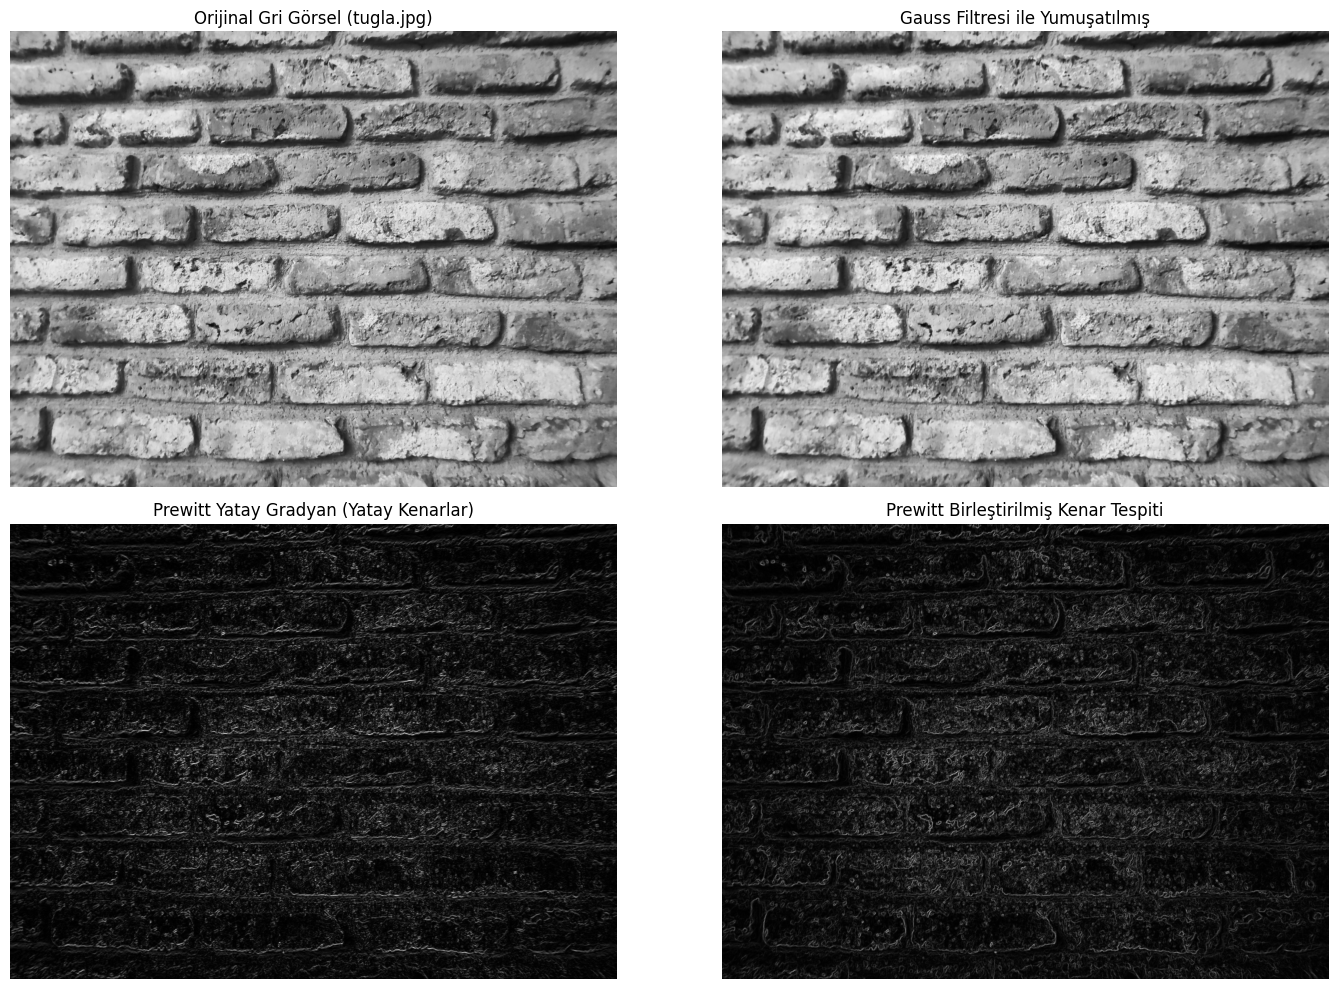

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Görüntüyü yükle ve gri tonlamaya çevir
img_path = 'tugla.jpg'
img_gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

if img_gray is None:
    print(f"Hata: '{img_path}' dosyası bulunamadı! Lütfen dosya yolunun doğru olduğundan veya dosyanın yüklendiğinden emin olun.")
    # Test amaçlı geçici bir yapay görsel oluşturalım
    print("Test için geçici bir yapay görsel oluşturuluyor...")
    img_gray = np.zeros((400, 400), dtype=np.uint8)
    cv2.putText(img_gray, 'TUGLA', (50, 220), cv2.FONT_HERSHEY_SIMPLEX, 3, 255, 10, cv2.LINE_AA)

try:
    # --- CUDA İLE İŞLEME ---
    # Görüntüyü GPU belleğine aktar
    gpu_img = cv2.cuda_GpuMat()
    gpu_img.upload(img_gray)

    # Gauss Yumuşatma Filtresi (Kernel: 5x5, Sigma: 1.0)
    gpu_blur_filter = cv2.cuda.createGaussianFilter(cv2.CV_8UC1, cv2.CV_8UC1, (5, 5), 1.0)
    gpu_blurred = gpu_blur_filter.apply(gpu_img)

    # Prewitt Yatay ve Dikey Çekirdek Tanımlamaları
    # Prewitt Yatay (Yatay kenarları belirginleştirir)
    kernel_x = np.array([[-1, -1, -1],
                         [ 0,  0,  0],
                         [ 1,  1,  1]], dtype=np.float32)

    # Prewitt Dikey (Dikey kenarları belirginleştirir)
    kernel_y = np.array([[-1,  0,  1],
                         [-1,  0,  1],
                         [-1,  0,  1]], dtype=np.float32)

    # CUDA Filtrelerini Oluştur
    filter_x = cv2.cuda.createLinearFilter(cv2.CV_8UC1, cv2.CV_16SC1, kernel_x)
    filter_y = cv2.cuda.createLinearFilter(cv2.CV_8UC1, cv2.CV_16SC1, kernel_y)

    # Filtreleri Uygula (Sonuçlar işaretli 16-bit integer olarak alınır)
    gpu_grad_x = filter_x.apply(gpu_blurred)
    gpu_grad_y = filter_y.apply(gpu_blurred)

    # Sonuçları CPU'ya geri yükle
    grad_x = gpu_grad_x.download()
    grad_y = gpu_grad_y.download()
    blurred_img = gpu_blurred.download()

    # Mutlak değerleri al ve 8-bit formatına dönüştür
    abs_grad_x = cv2.convertScaleAbs(grad_x)
    abs_grad_y = cv2.convertScaleAbs(grad_y)

    # Yatay ve dikey gradyanları birleştir (Prewitt Genliği)
    prewitt_combined = cv2.addWeighted(abs_grad_x, 0.5, abs_grad_y, 0.5, 0)
    print("İşlemler CUDA (GPU) kullanılarak başarıyla tamamlandı.")

except Exception as e:
    print(f"CUDA ile işlem sırasında hata oluştu: {e}\nİşleme CPU ile devam ediliyor...")
    # --- CPU YEDEK PLANI (FALLBACK) ---
    # Gauss Yumuşatma
    blurred_img = cv2.GaussianBlur(img_gray, (5, 5), 1.0)

    kernel_x = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)
    kernel_y = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)

    grad_x = cv2.filter2D(blurred_img, cv2.CV_16S, kernel_x)
    grad_y = cv2.filter2D(blurred_img, cv2.CV_16S, kernel_y)

    abs_grad_x = cv2.convertScaleAbs(grad_x)
    abs_grad_y = cv2.convertScaleAbs(grad_y)
    prewitt_combined = cv2.addWeighted(abs_grad_x, 0.5, abs_grad_y, 0.5, 0)

# --- GÖRSELLEŞTİRME ---
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Orijinal Gri Görsel (tugla.jpg)')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(blurred_img, cmap='gray')
plt.title('Gauss Filtresi ile Yumuşatılmış')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(abs_grad_x, cmap='gray')
plt.title('Prewitt Yatay Gradyan (Yatay Kenarlar)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(prewitt_combined, cmap='gray')
plt.title('Prewitt Birleştirilmiş Kenar Tespiti')
plt.axis('off')

plt.tight_layout()
plt.show()